# Sattelite Image Classifier

Author: Ivan Novikov

Student ID: K62405902

In [13]:
# This is just a minimum setup for reproducibility. Add more libraries as required.

import numpy as np
import torch
import matplotlib.pyplot as plt
import os
import pandas as pd

# Setting device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.backends.mps.is_available(): device = torch.device("mps")

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)

In [14]:
# checking successful setup
print(f"Using device: {device}")

Using device: cpu


In [15]:
# For visualization in Jupyter notebooks
%matplotlib inline

In [16]:
# Set working directory to the project folder
os.chdir(r"C:\Users\pyotr\Desktop\JKU studies\Programming for AI II\my_project_folder")  # Change this to your project folder path
print(f"Current working directory: {os.getcwd()}")

Current working directory: C:\Users\pyotr\Desktop\JKU studies\Programming for AI II\my_project_folder


In [17]:
# creating folder 'assets' if necessary
os.makedirs("assets", exist_ok=True)

## Data Handling and Pre-Processing

In [18]:
# your code goes here (preprocess function)
def preprocess(data_folder: str)-> tuple[pd.DataFrame, dict]:
    """
    returns:
        • A DataFrame that holds the file path, file name and a numeric label for every image.
        • A dictionary that maps the numeric labels to the class names
    """

    data_folder_reader = os.listdir(data_folder)       # reading the dataset folder

    # Dictionary (enumerating labels)
    dict_label = {}
    label_counter = 0
    for folder in data_folder_reader:                   # add each folder to dict, increase index by 1
        dict_label[folder] = label_counter; label_counter += 1   
    
    # Data Frame
    dict_data = {'folder': [],                          # creat a dictionary that would be converted to DF
                 'file_name': [],
                 'label': []}
    
    df_label_counter = 0
    for folder in data_folder_reader:
        full_folder_path = os.path.join(data_folder, folder)         # get a filepath for each file
        files_reader = os.listdir(full_folder_path)

        for file in files_reader:
            dict_data['folder'].append(full_folder_path)             # append dictionary with folder paths, file names and label n.
            dict_data['file_name'].append(os.path.basename(file))
            dict_data['label'].append(df_label_counter)
        
        df_label_counter += 1                                        # update label counter for each folder      

    DataFrame = pd.DataFrame(dict_data)                              # convert dict to DF

    return DataFrame, dict_label

In [ ]:
# checking successful dataframe loading
DataFrame = preprocess(r"C:\Users\pyotr\Desktop\JKU studies\Programming for AI II\my_project_folder\data sets\data")[0]               #change this to your own path, obviously
dictionary_labels = preprocess(r"C:\Users\pyotr\Desktop\JKU studies\Programming for AI II\my_project_folder\data sets\data")[1]

# uncomment after preprocessing the dataset and adapt the variable name
print(f"Length of dataset: {len(DataFrame)}") # Should be 10000


Length of dataset: 10000


In [20]:
# your code goes here (splitting train/validation datasets)
from sklearn.model_selection import train_test_split     # right as suggested in instruction document, importing train_test_split function

train_df, val_df = train_test_split(
    DataFrame,
    test_size=0.15,                # i.e. i decided to use 85/15 split
    stratify=DataFrame["label"],   # stratifying by "labels" - i.e. all classes
    random_state=42)


## Exploratory Data Analysis (EDA)

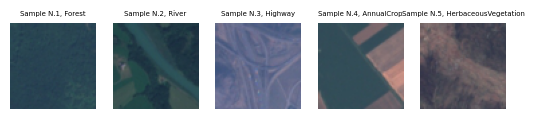

In [21]:
# your code goes here (show_samples)
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import random as rand

def show_samples(df: pd.DataFrame, num_samples: int = 5)-> None:
    """randomly selects num_samples images from the DataFrame and displays them in a grid"""
    
    fig = plt.figure()
    samples_indexes = []

    for n in range(num_samples):                  # generating n random indexes
        index = rand.randint(0, 9999)

        while index in samples_indexes:           # in case indexes are repeating
            index = rand.randint(0, 9999)

        samples_indexes.append(index)

    
    n = 1
    for index in samples_indexes:
        image_name = df.loc[index, "file_name"]
        image_path = df.loc[index, "folder"]
        image = os.path.join(image_path, image_name)     # pulling together precise filepath

        image_label = df.loc[index, 'label']
        key = next((k for k, v in dictionary_labels.items() if v == image_label), None)      # and pulling label class for better visual representation

        img = mpimg.imread(image)                      # reading image, appending it to the general plot, visual edits
        plt.subplot(1, num_samples, n)     
        plt.imshow(img)  
        plt.axis('off')
        plt.title(f"Sample N.{n}, {key}", fontsize=5)

        n += 1

    # saving plot to the directory
    os.makedirs("assets/plots", exist_ok=True)                                     # checking if directory even exists
    plt.savefig("assets/plots/random_samples.png", dpi=300, bbox_inches="tight")   # saving file

    plt.show()


show_samples(DataFrame, 5)

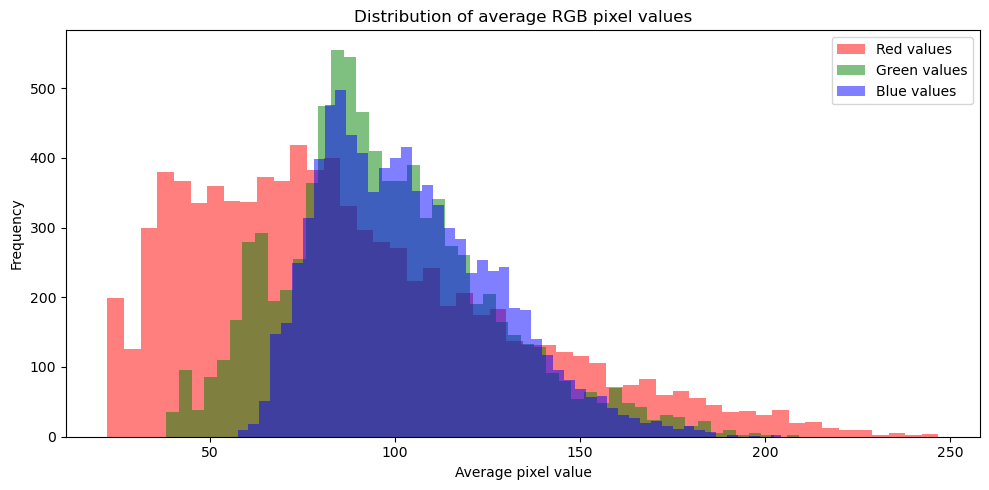

In [22]:
# your code goes here (average_pixel_plot)

def average_pixel_plot(df: pd.DataFrame)-> None:
    """creates a plot that shows the distribution of the average pixel values in the three color channels in the training set."""
 
    rgb_dict = {"red": [],                       # creating dictionary for rgb values of each image
                "green": [],
                "blue": []}
    
    for index in df.index:                            # i.e. checking every image
        image_name = df.loc[index, "file_name"]
        image_path = df.loc[index, "folder"]
        image = os.path.join(image_path, image_name)   # getting full image filepath

        img = mpimg.imread(image)                       # reading image, getting an array shaped like this - (height, width, 3)

        red, green, blue = img[:, :, 0], img[:, :, 1], img[:, :, 2]    # slicing via indexing to get values individually
        rgb_dict["red"].append(red.mean()), rgb_dict["green"].append(green.mean()), rgb_dict["blue"].append(blue.mean())  # and appending to the dictionary


    plt.figure(figsize=(10, 5))             # now to plotting and visualizing:

    plt.hist(rgb_dict['red'], bins=50, alpha=0.5, color="red", label="Red values")          # plotting histogramms per color
    plt.hist(rgb_dict['green'], bins=50, alpha=0.5, color="green", label="Green values")
    plt.hist(rgb_dict['blue'], bins=50, alpha=0.5, color="blue", label="Blue values")

    plt.xlabel("Average pixel value")                             # visual details: axis names, legend etc.
    plt.ylabel("Frequency")
    plt.title("Distribution of average RGB pixel values")
    plt.legend()
    plt.tight_layout()

    # saving plot to the directory
    os.makedirs("assets/plots", exist_ok=True)                                                 # checking if directory even exists
    plt.savefig("assets/plots/average_pixel_distribution.png", dpi=300, bbox_inches="tight")   # saving file

    plt.show()


average_pixel_plot(train_df)

C:\Users\pyotr\AppData\Local\Temp\ipykernel_21768\605387390.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([brightness_dict[k] for k in brightness_dict], labels=[k for k in brightness_dict])   # boxplot per class


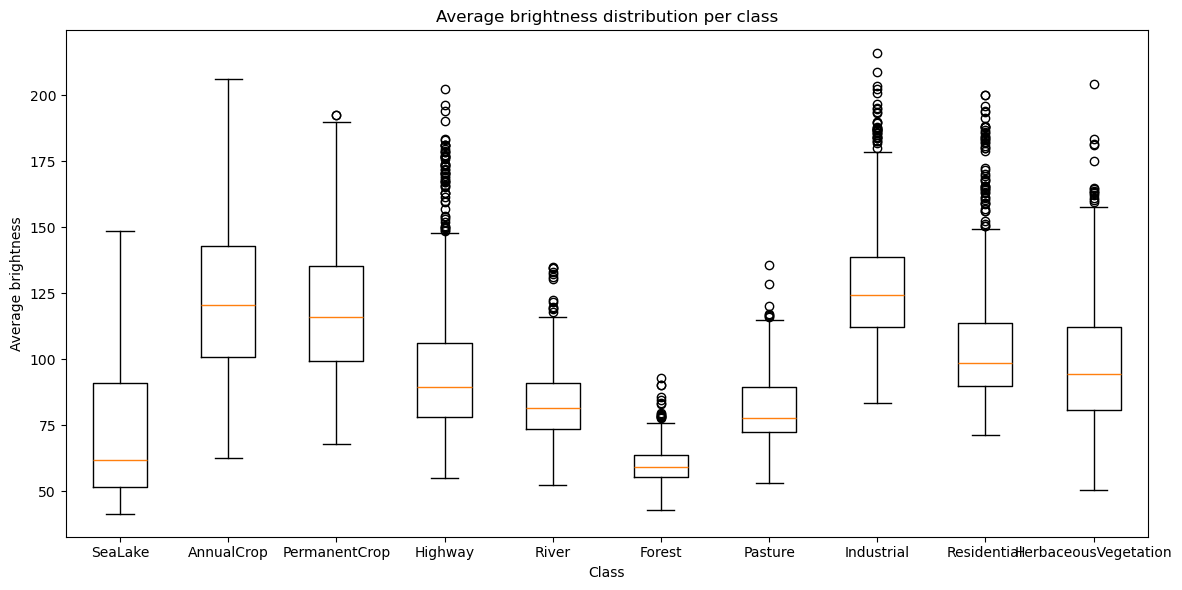

In [23]:
# your code goes here (average_brightness_per_class)

def average_brightness_per_class(df: pd.DataFrame)-> None:
    """creates a boxplot that shows the distribution of the average brightness
    (i.e. average pixel value across all three color channels) for each class in the training set."""

    brightness_dict = {}
    reverse_labels = {v: k for k, v in dictionary_labels.items()}             # we need it for future simplier data appending, i'm too lazy to fix the entire structure

    for index in df.index:                            
        image_name = df.loc[index, "file_name"]
        image_path = df.loc[index, "folder"]
        image = os.path.join(image_path, image_name)  

        img = mpimg.imread(image)        # up to this point, exactly the same methodology as with rgb plot
        brightness = img.mean()          # but in here, brightness is just mean of all three r, g and b values

        image_label = df.loc[index, 'label']         # pulling label class
        class_name = reverse_labels[image_label]   
        brightness_dict.setdefault(class_name, []).append(brightness)    # appending brightness value to dict

    # and now to creating a boxplot
    plt.figure(figsize=(12, 6))
    plt.boxplot([brightness_dict[k] for k in brightness_dict], labels=[k for k in brightness_dict])   # boxplot per class
    plt.xlabel("Class")
    plt.ylabel("Average brightness")
    plt.title("Average brightness distribution per class")
    plt.tight_layout()
    
    # saving plot to the directory
    os.makedirs("assets/plots", exist_ok=True)                                         # checking if directory even exists
    plt.savefig("assets/plots/average_brightness.png", dpi=300, bbox_inches="tight")   # saving file

    plt.show()

average_brightness_per_class(train_df)  

In [24]:
def get_mean(df: pd.DataFrame) -> None:
    """computing df's RGB mean for transofrmations (look in CNN step)"""
    rgb_dict = {"red": [],                       # creating dictionary for rgb values of each image
                "green": [],
                "blue": []}
    
    for index in df.index:                            # i.e. checking every image
        image_name = df.loc[index, "file_name"]
        image_path = df.loc[index, "folder"]
        image = os.path.join(image_path, image_name)   # getting full image filepath

        img = mpimg.imread(image)                       # reading image, getting an array shaped like this - (height, width, 3)

        red, green, blue = img[:, :, 0], img[:, :, 1], img[:, :, 2]    # slicing via indexing to get values individually
        rgb_dict["red"].append(red.mean()), rgb_dict["green"].append(green.mean()), rgb_dict["blue"].append(blue.mean())  # and appending to the dictionary

    # so far, exactly the same approach as before, but now:

    l_red, l_green, l_blue = len(rgb_dict['red']), len(rgb_dict['green']), len(rgb_dict['blue'])
    s_red, s_green, s_blue = sum(rgb_dict['red']), sum(rgb_dict['green']), sum(rgb_dict['blue'])

    mean = [(s_red/l_red)/255, (s_green/l_green)/255, (s_blue/l_blue)/255]
    return mean



def get_std(df: pd.DataFrame) -> list:
    """computing df's RGB std for transformations (look in CNN step)"""
    std_dict = {"red": [], "green": [], "blue": []}

    for index in df.index:
        image_name = df.loc[index, "file_name"]
        image_path = df.loc[index, "folder"]
        image = os.path.join(image_path, image_name)

        img = mpimg.imread(image)

        red, green, blue = img[:, :, 0], img[:, :, 1], img[:, :, 2]

        # computing per image std
        std_dict["red"].append(red.std()), std_dict["green"].append(green.std()), std_dict["blue"].append(blue.std())

    # average the per image stds
    l_red, l_green, l_blue = len(std_dict['red']), len(std_dict['green']), len(std_dict['blue'])
    s_red, s_green, s_blue = sum(std_dict['red']), sum(std_dict['green']), sum(std_dict['blue'])

    std = [(s_red/l_red)/255, (s_green/l_green)/255, (s_blue/l_blue)/255]
    return std

mean = get_mean(train_df)
std = get_std(train_df)

print(mean, std)



    

[np.float64(0.3454906814311202), np.float64(0.3821572564112961), np.float64(0.4091499240826845)] [np.float64(0.09406774456234863), np.float64(0.06586975807942382), np.float64(0.05506130168200451)]


## CNN Implementation and Training

### Dataset class

In [25]:
# your code goes here
from torch.utils.data import Dataset
import torchvision.transforms as T            # for transformations, as in outline / guideline 
from PIL import Image

train_transform = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(mean, std),
])

val_transform =   T.Compose([T.Resize((64, 64)), T.ToTensor(), T.Normalize(mean, std)])


class MyDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform
        self.has_labels = "label" in df.columns  # chekhov's gun, we would need it only later for test set

    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, index):
        # 0. get a needed row
        row = self.df.iloc[index]

        # 1. get file path                        
        image_name = row["file_name"]
        image_path = row["folder"]
        img_path = os.path.join(image_path, image_name)

        # 2. load image
        img = Image.open(img_path).convert('RGB')

        # 3. apply transformations
        if self.transform:
            img = self.transform(img)

        # 5. ... and return!
        if self.has_labels:
            label = row["label"]
            return img, label
        else:
            return img, image_name   # return filename for submission

    
    
train_dataset = MyDataset(train_df, transform=train_transform)
val_dataset   = MyDataset(val_df,   transform=val_transform)





In [26]:
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)


### Data Loaders

In [27]:
# your code goes here
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,               # shuffling for the training, mais...
    num_workers=0,    
    pin_memory=True)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,              # ...going in order for validation.
    num_workers=0,            # my cpu isn't the best, 
    pin_memory=True)


### Model Architecture

In [28]:
# your code goes here
                                  # main comment - i have no comments, whatever this whole pytorch thing is...
import torch
import torch.nn as nn
import torch.nn.functional as F

class BasicBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride=stride, padding=1)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(nn.Conv2d(in_c, out_c, 1, stride=stride), nn.BatchNorm2d(out_c))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return F.relu(out)

class ResNetSmall(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.layer1 = BasicBlock(3, 32)
        self.layer2 = BasicBlock(32, 64, stride=2)
        self.layer3 = BasicBlock(64, 128, stride=2)
        self.layer4 = BasicBlock(128, 256, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.pool(x).view(x.size(0), -1)
        return self.fc(x)


### Training Loop

In [29]:
# your code goes here

from torch.optim import Adam
from torch.optim.lr_scheduler import StepLR

def train_model(model, train_loader, val_loader, num_epochs=35, patience=10):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = Adam(model.parameters(), lr=5e-4)
    scheduler = StepLR(optimizer, step_size=5, gamma=0.5)
    

    best_val_acc = 0
    patience_counter = 0

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0 
        correct = 0 
        total = 0

        # training loop
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = correct / total

        # validation loop
        model.eval()
        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()

                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_loss /= len(val_loader)
        val_acc = val_correct / val_total

        # save history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

        # save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), "assets/weights/best_model.pth")
        else:
            patience_counter += 1

        # early stop
        if patience_counter >= patience:
            print("Early stopping triggered.")
            break

        # scheduler
        scheduler.step()

    return history

In [ ]:
os.makedirs("assets/weights", exist_ok=True)

num_classes = len(train_df["label"].unique())
model = ResNetSmall(num_classes)

history = train_model(model, train_loader, val_loader, num_epochs=40, patience=10)

c:\Users\pyotr\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 1/40 | Train Loss: 1.4687 | Train Acc: 0.5667 | Val Loss: 1.2822 | Val Acc: 0.6560
Epoch 2/40 | Train Loss: 1.2127 | Train Acc: 0.6868 | Val Loss: 1.0676 | Val Acc: 0.7487
Epoch 3/40 | Train Loss: 1.0872 | Train Acc: 0.7419 | Val Loss: 1.0551 | Val Acc: 0.7733
Epoch 4/40 | Train Loss: 1.0078 | Train Acc: 0.7846 | Val Loss: 1.2575 | Val Acc: 0.7340
Epoch 5/40 | Train Loss: 0.9287 | Train Acc: 0.8240 | Val Loss: 0.8529 | Val Acc: 0.8580
Epoch 6/40 | Train Loss: 0.8421 | Train Acc: 0.8627 | Val Loss: 0.7979 | Val Acc: 0.8907
Epoch 7/40 | Train Loss: 0.8132 | Train Acc: 0.8782 | Val Loss: 0.8413 | Val Acc: 0.8733
Epoch 8/40 | Train Loss: 0.7879 | Train Acc: 0.8925 | Val Loss: 0.8449 | Val Acc: 0.8707
Epoch 9/40 | Train Loss: 0.7663 | Train Acc: 0.9007 | Val Loss: 0.7492 | Val Acc: 0.9060
Epoch 10/40 | Train Loss: 0.7586 | Train Acc: 0.9012 | Val Loss: 0.7523 | Val Acc: 0.9047
Epoch 11/40 | Train Loss: 0.7210 | Train Acc: 0.9216 | Val Loss: 0.7061 | Val Acc: 0.9220
Epoch 12/40 | Train

## Model Evaluation

In [30]:
# your code goes here (plot_training_curves)

def plot_training_curves(history):
    plt.figure(figsize=(14, 5))

    # left plot - loss curves
    plt.subplot(1, 2, 1)
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training & Validation Loss")
    plt.legend()
    plt.grid(True)

    # right plot - validation accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history["val_acc"], label="Validation Accuracy", color="green")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Validation Accuracy")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_curves(history)

NameError: name 'history' is not defined

<Figure size 1600x1600 with 0 Axes>

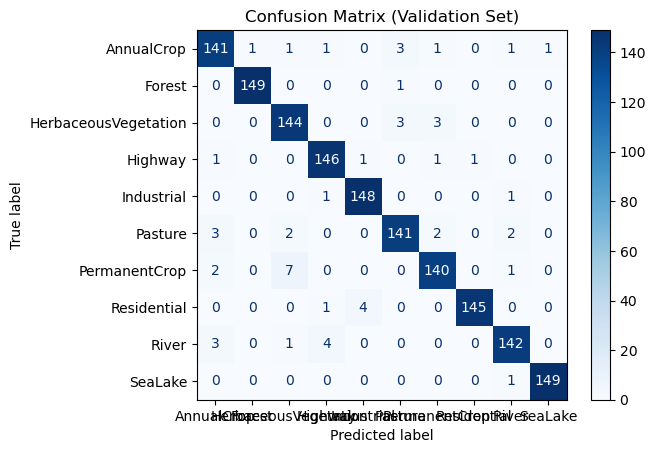

In [ ]:
# your code goes here (plot_confusion_matrix)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion_matrix(model, val_loader, class_names):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = outputs.max(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    plt.figure(figsize=(16, 16))
    disp.plot(cmap="Blues", values_format="d")
    plt.title("Confusion Matrix (Validation Set)")
    plt.show()

class_names = []
for index in DataFrame.index:
    image_label = DataFrame.loc[index, 'label']
    key = next((k for k, v in dictionary_labels.items() if v == image_label), None)
    if key not in class_names: class_names.append(key) 

plot_confusion_matrix(model, val_loader, class_names)


In [ ]:
# your code goes here (plot_misclassified_samples)


def show_misclassified(model, val_loader, class_names, samples=5):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()

    misclassified_images = []
    misclassified_true = []
    misclassified_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, preds = outputs.max(1)

            for img, true, pred in zip(images, labels, preds):
                if true != pred:
                    misclassified_images.append(img.cpu())
                    misclassified_true.append(true.cpu().item())
                    misclassified_pred.append(pred.cpu().item())
                if len(misclassified_images) >= samples: break
            if len(misclassified_images) >= samples: break

    # plot itself
    plt.figure(figsize=(15, 5))
    for i in range(samples):
        img = misclassified_images[i].permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)  # valid range

        true_label = class_names[misclassified_true[i]]
        pred_label = class_names[misclassified_pred[i]]

        plt.subplot(1, samples, i + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"True: {true_label}\nPred: {pred_label}")

    plt.tight_layout()
    plt.show()


show_misclassified(model, val_loader, class_names, samples=5)


NameError: name 'model' is not defined

### Test Set

In [ ]:
# your code goes here (preprocess_test_data)

test_folder = r"data sets/public_test_data"

def preprocess_test(data_folder: str) -> pd.DataFrame:
    """ Creates a DataFrame for the test set, returns DataFrame with columns: 'folder', 'file_name'"""
    
    test_files = sorted([f for f in os.listdir(test_folder) if f.endswith(".jpg")], key=lambda x: int(x.replace(".jpg", "")))
    df_test = pd.DataFrame({"file_name": test_files})
    df_test["folder"] = test_folder

    return df_test


print(preprocess_test(test_folder))

     file_name                      folder
0        2.jpg  data sets/public_test_data
1        5.jpg  data sets/public_test_data
2       12.jpg  data sets/public_test_data
3       23.jpg  data sets/public_test_data
4       25.jpg  data sets/public_test_data
...        ...                         ...
1975  9985.jpg  data sets/public_test_data
1976  9987.jpg  data sets/public_test_data
1977  9991.jpg  data sets/public_test_data
1978  9995.jpg  data sets/public_test_data
1979  9996.jpg  data sets/public_test_data

[1980 rows x 2 columns]


In [ ]:
# your code goes here (create dataset and dataloader)

test_df = preprocess_test(test_folder)
test_dataset = MyDataset(test_df, transform=val_transform)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=0)


model = ResNetSmall(num_classes)
model.load_state_dict(torch.load("assets/weights/best_model.pth", map_location="cpu"))
model.eval()

ResNetSmall(
  (layer1): BasicBlock(
    (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (shortcut): Sequential(
      (0): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
  )
  (layer2): BasicBlock(
    (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (shortcut): 

In [ ]:
for images, file_names in test_loader:
    print(file_names[:5])
    break

('2.jpg', '5.jpg', '12.jpg', '23.jpg', '25.jpg')


In [ ]:
# your code goes here (evaluate model on test set)

all_files = []
all_preds = []

with torch.no_grad():
    for images, file_names in test_loader:   # ie any names as test set has no names apparently??
        outputs = model(images)
        _, preds = outputs.max(1)

        all_files.extend(file_names)
        all_preds.extend(preds.cpu().numpy())

remap = {
    0: 1,
    1: 7,
    2: 0,
    3: 6,
    4: 4,
    5: 3,
    6: 8,
    7: 2,
    8: 5,
    9: 9
}

server_labels = [
    "HerbaceousVegetation",
    "AnnualCrop",
    "Residential",
    "Pasture",
    "Industrial",
    "River",
    "Highway",
    "Forest",
    "PermanentCrop",
    "SeaLake"
]





In [ ]:
# your code goes here (create submission csv file for challenge server)

with open("submission.csv", "w") as f:
    for filename, pred in zip(all_files, all_preds):
        corrected_index = remap[int(pred)]
        class_name = server_labels[corrected_index]
        f.write(f"{filename},{class_name}\n")